<a href="https://colab.research.google.com/github/cmd0850/Chislovy_metodi/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D0%B3%D1%87%D0%B0%D0%BA%D0%BE_%D0%BB%D0%B110.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
!pip install -q kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

Завантаження даних

In [2]:
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
/kaggle/input/gtsrb-german-traffic-sign
['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


Виконаня

In [4]:
def load(csv_name):
    df = pd.read_csv(os.path.join(path, csv_name))
    images = []
    for p in df["Path"]:
        img = Image.open(os.path.join(path, p)).convert("RGB").resize((32, 32))
        images.append(np.array(img))
    return np.array(images) / 255.0, df["ClassId"].values

x_train, y_train = load("Train.csv")
x_test, y_test = load("Test.csv")

print(x_train.shape, x_test.shape)

(39209, 32, 32, 3) (12630, 32, 32, 3)


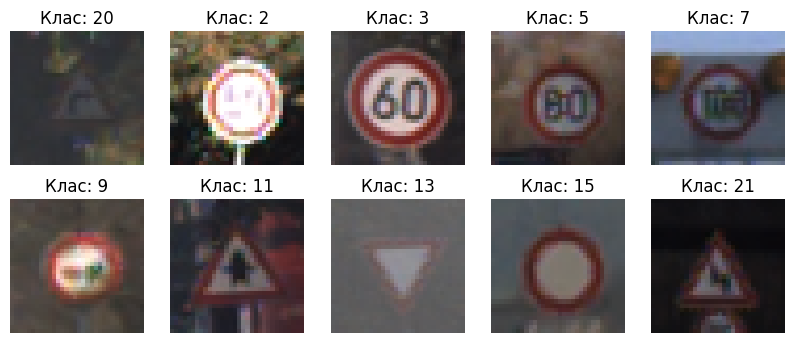

In [5]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i * 3000])
    plt.title(f"Клас: {y_train[i * 3000]}")
    plt.axis("off")
plt.show()

In [6]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(43, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,979 (1.22 MB)

 Trainable params: 319,979 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

history = model.fit(x_tr, y_tr,
                    epochs=10,
                    batch_size=64,
                    validation_data=(x_val, y_val))

Epoch 1/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 43s 87ms/step - accuracy: 0.9229 - loss: 0.3088 - val_accuracy: 0.9918 - val_loss: 0.0380
Epoch 2/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 83s 90ms/step - accuracy: 0.9752 - loss: 0.0821 - val_accuracy: 0.9966 - val_loss: 0.0205
Epoch 3/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 42s 86ms/step - accuracy: 0.9842 - loss: 0.0522 - val_accuracy: 0.9967 - val_loss: 0.0194
Epoch 4/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 42s 86ms/step - accuracy: 0.9881 - loss: 0.0394 - val_accuracy: 0.9963 - val_loss: 0.0168
Epoch 5/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 82s 86ms/step - accuracy: 0.9895 - loss: 0.0343 - val_accuracy: 0.9973 - val_loss: 0.0152
Epoch 6/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 42s 86ms/step - accuracy: 0.9911 - loss: 0.0304 - val_accuracy: 0.9974 - val_loss: 0.0154
Epoch 7/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 43s 87ms/step - accuracy: 0.9908 - loss: 0.0316 - val_accuracy: 0.9976 - val_loss: 0.0159
Epoch 8/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 82s 86ms/step - accuracy: 0.9937 - loss: 0.0207 - 

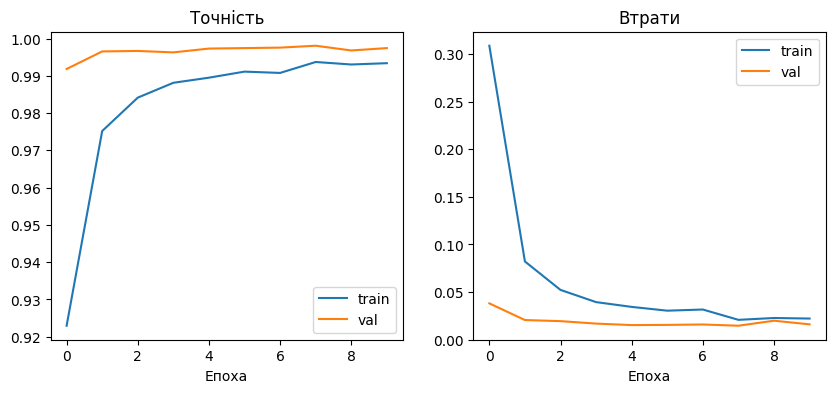

In [14]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Точність")
plt.xlabel("Епоха")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Втрати")
plt.xlabel("Епоха")
plt.legend()

plt.show()

In [15]:
loss, acc = model.evaluate(x_test, y_test)
print("Точність на тесті:", acc)

395/395 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9575 - loss: 0.2388
Точність на тесті: 0.9574821591377258


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step


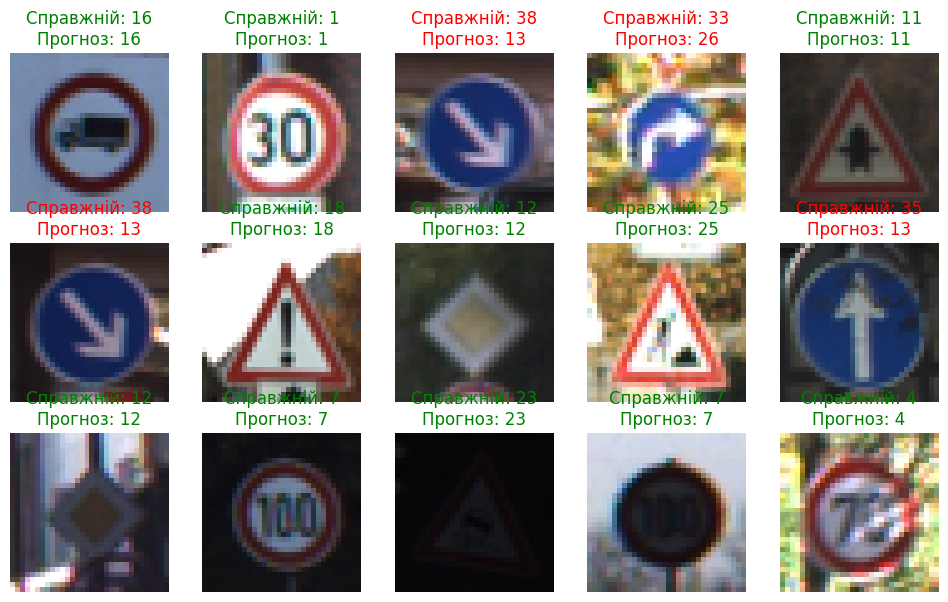

In [10]:
pred = np.argmax(model.predict(x_test[:15]), axis=1)

plt.figure(figsize=(12, 7))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i])
    color = "green" if pred[i] == y_test[i] else "red"
    plt.title(f"Справжній: {y_test[i]}\nПрогноз: {pred[i]}", color=color)
    plt.axis("off")
plt.show()

Висновок: в результаті точність вийшла більше  95%, модель працює добре.Помилки у класах 35 і 38 бо вони схожі і якість зображень мала. тому плутає з 13. Для покращення можна було б збільшити кількість епох